# Anomaly detection in component temperatures

In this notebook we illustrate examples of anomalous temperature measurement in a certain component of a complex multi-component system (e.g wind turbine).

We analyse two examples:
1. Univariate case: the component is isolated from the environment. Its temperature is uncorrelated with any other temperature. Anomalously high temperatures are easy to detect.
2. Multivariate case: the component's temperature is influenced by the ambient temperature. Anomalous temepratures must be detected by developing a model for normality and measuring deviations from it.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Univariate example: isolated bearing temperature
The component is isolated from the ambient temperature. Detect abnormal condition using the component temperature.

## Read data
using url to a shared google drive

In [2]:
url = "https://drive.google.com/uc?export=download&id=1ScJqZGQJvv5YiQAs_56CiH2_cPlOKlIn"

# Load the CSV into a DataFrame directly from the URL
data = pd.read_csv(url)

# Display the data to confirm
data


,Time (days),Bearing Temperature,Label
0,0.000000,30.124179,0.0
1,0.041725,29.965434,0.0
2,0.083449,30.161922,0.0
3,0.125174,30.380757,0.0
4,0.166898,29.941462,0.0
...,...,...,...
715,29.833102,30.275825,0.0
716,29.874826,30.028557,0.0
717,29.916551,30.037575,0.0
718,29.958275,29.909097,0.0


## Visualize data

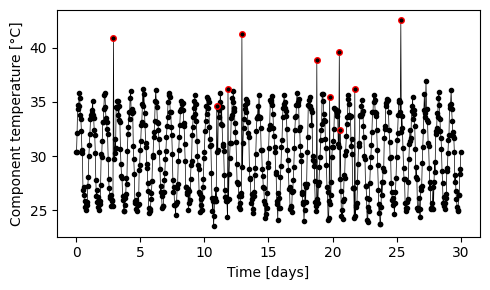

In [18]:
# Highlight true anomalies with large empty yellow squares
true_anomalies = data[data['Label']==1]  # Use the indices of the true anomalies


plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=4)
plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.tight_layout()
#plt.savefig('BearingTempIsolated.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTempIsolated.pdf')

## detect anomalies with a statistical threshold
The simplest strategy to detect anomalies in a univariate data is to select a decision threshold beyond which the data is considered anomalous. Here we use the empirical statistical properties of the data to determine the threshold.

## Histogram

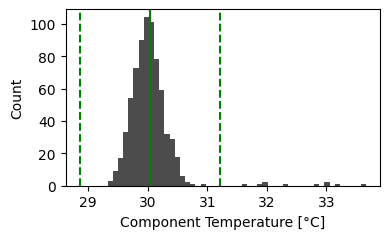

In [4]:
# calculate sample mean and std
temp_mean,temp_std = np.mean(data['Bearing Temperature']),np.std(data['Bearing Temperature'])
# determine upper and lower thresholds
threshold_up = temp_mean+3*temp_std
threshold_low = temp_mean-3*temp_std
# detect anomalies using the boundaries
detect = (data['Bearing Temperature']>threshold_up) |  (data['Bearing Temperature']<threshold_low)
detected_anomalies = data[detect==1]


# plot histogram with decision boundary
plt.figure(figsize=(4,2.5))
BearTempHist = plt.hist(data['Bearing Temperature'],50,color='k',alpha=0.7)

plt.axvline(temp_mean,color='g')
plt.axvline(threshold_up,color='g',ls='--')
plt.axvline(threshold_low,color='g',ls='--')

plt.xlabel('Component Temperature [°C]')
plt.ylabel('Count')

plt.tight_layout()
#plt.savefig('BearingTempIsolated_hist.pdf')  # Save the figure
plt.show()
# Download the figure
#files.download('BearingTempIsolated_hist.pdf')


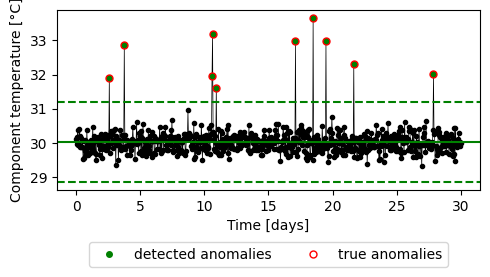

In [5]:
# plot time series data with decision boundary
plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)

plt.axhline(y=temp_mean,color='g')
plt.axhline(threshold_up,color='g',ls='--')
plt.axhline(threshold_low,color='g',ls='--')

# mark detected anomalies
plt.plot(detected_anomalies['Time (days)'],detected_anomalies['Bearing Temperature'],'go',ms=4,label='detected anomalies')
# compare with true anomalies
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=5,label='true anomalies')

plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)

plt.tight_layout()
#plt.savefig('BearingTempIsolated_statThresh.pdf')  # Save the figure
plt.show()
# Download the figure
#files.download('BearingTempIsolated_statThresh.pdf')


## Think
1. did we use the labels to detect anomalies?
2. what happens if the anomalies are less pronounced?
3. what changes if the component is not isolated from the surrounding and is affected by the ambient temperature?

# Multivariate example bearing temperature
In this example the component (e.g a bearing) is not isolated from its surrounding, and its temperature correlates storngly with the ambient temperature.

## Read data
using url to a shared google drive

In [6]:
url = "https://drive.google.com/uc?export=download&id=1-1NxIsRyVXE4gu3ZrYJu8YfcYKBvGKB9"


# Load the CSV into a DataFrame directly from the URL
data = pd.read_csv(url)

# Display the data to confirm
data


,Time (days),Ambient Temperature,Bearing Temperature,Label
0,0.000000,20.248357,30.402258,0.0
1,0.041725,21.226722,30.371637,0.0
2,0.083449,22.826997,32.152904,0.0
3,0.125174,24.300909,34.672541,0.0
4,0.166898,24.216687,34.302120,0.0
...,...,...,...,...
715,29.833102,16.217887,26.359177,0.0
716,29.874826,16.517720,26.393374,0.0
717,29.916551,17.571998,28.375671,0.0
718,29.958275,18.522340,28.767828,0.0


## visualize data

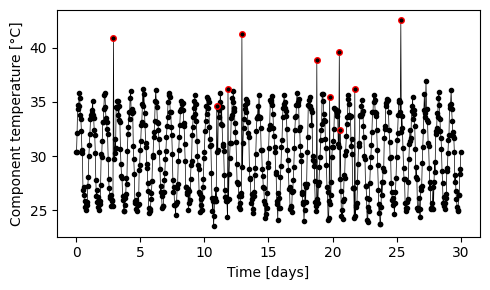

In [7]:
# Highlight true anomalies with large empty yellow squares
true_anomalies = data[data['Label']==1]  # Use the indices of the true anomalies

plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=4)
plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.tight_layout()
#plt.savefig('BearingTempAmbient.pdf')  # Save the figure

# Download the figure
#files.download('BearingTempAmbient.pdf')

Some of the marked anomalies have lower temperatures than some of the normal data. Let us zoom in to look at them.

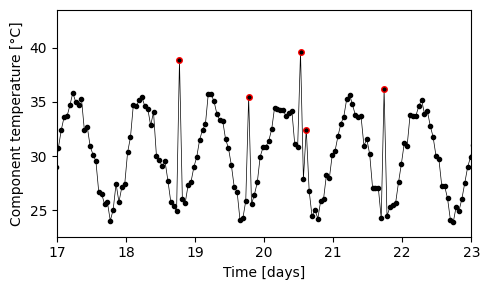

In [8]:
# Zoom in
plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=4)
plt.xlim(17,23)
plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.tight_layout()
#plt.savefig('BearingTempAmbientZoomIn.pdf')  # Save the figure

# Download the figure
#files.download('BearingTempAmbientZoomIn.pdf')

## Visualize all variables

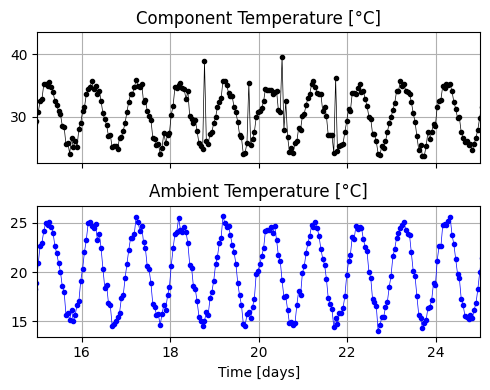

In [9]:
# Create subplots for the variables
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(5, 4), sharex=True)
xlimit = [15,25]
# Plot bearing temperature
axes[0].plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
axes[0].set_title("Component Temperature [°C]")
axes[0].grid(True)
axes[0].set_xlim(xlimit)
# Plot ambient temperature
axes[1].plot(data['Time (days)'], data['Ambient Temperature'],'b-o',lw=0.5,ms=3)
axes[1].set_xlabel("Time [days]")
axes[1].set_title("Ambient Temperature [°C]")
axes[1].grid(True)
plt.tight_layout()
#plt.savefig('BearingTempAmbientTemp.pdf')  # Save the figure
# Download the figure
#files.download('BearingTempAmbientTemp.pdf')

plt.show()


## Think
1. How are these anomalies different from the previous case?
2. Would a simple statistical threshold work here?
3. Any idea how to detect anomalies here?


## Correlations between variables: pair plot

In [10]:

import itertools

def pair_plot(df_data):
  # Create a pair plot
  num_vars = df_data.columns
  n = len(num_vars)

  fig, axes = plt.subplots(n, n, figsize=(5, 5))

  # Iterate through each subplot
  for i, j in itertools.product(range(n), range(n)):
      ax = axes[i, j]
      if i == j:
          # Diagonal: Plot histograms
          ax.hist(df_data[num_vars[i]], bins=50, color='lightblue', edgecolor='black')
          ax.set_title(num_vars[i])
      else:
          # Off-diagonal: Scatter plots
          ax.scatter(df_data[num_vars[j]], df_data[num_vars[i]], alpha=0.5, color='blue',s=2)

  # Adjust layout
  plt.tight_layout()
  plt.show()
  return fig,axes


In [ ]:
var_data = data[["Ambient Temperature","Bearing Temperature"]].copy()
fig,axes = pair_plot(var_data)

plt.tight_layout()
fig.savefig('BearingTempAmbient_PairPlot.pdf')  # Save the figure

# Download the figure
#files.download('BearingTempAmbient_PairPlot.pdf')

# AD with linear regression

In [11]:
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.metrics import mean_absolute_error

# Prepare the features and target
X = data['Ambient Temperature'].values.reshape(-1, 1)  # Feature: Ambient Temperature
y = data['Bearing Temperature'].values  # Target: Bearing Temperature

# Fit model 1 - Simple Linear Regression
model1 = LinearRegression()
model1.fit(X, y)
predictions1 = model1.predict(X)

# Calculate residuals for model 1
residuals1 = y - predictions1

# Add residuals as anomaly scores to the dataset
data['Residuals (Linear)'] = residuals1



## Plot linear regression

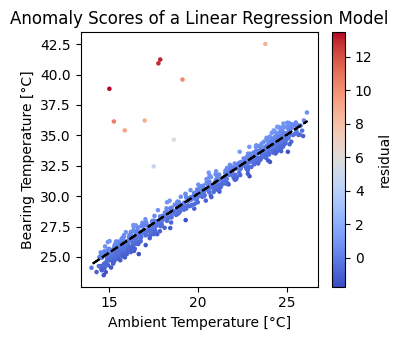

In [12]:
# Visualize the data in feature space (Ambient vs Bearing Temperature) and color by anomaly score
plt.figure(figsize=(4, 3.5))
# Scatter plot with color representing anomaly score
scatter = plt.scatter(data["Ambient Temperature"], data["Bearing Temperature"], c=residuals1, cmap='coolwarm',  s=5)
# Add color bar to indicate anomaly score levels
plt.colorbar(scatter, label='residual')
# plot the linear regression prediction
plt.plot(data["Ambient Temperature"],predictions1,'k--')
# Labels and title
plt.title("Anomaly Scores of a Linear Regression Model")
plt.xlabel("Ambient Temperature [°C]")
plt.ylabel("Bearing Temperature [°C]")
plt.tight_layout()
#plt.savefig('BearingTemp_AnomalyScores.pdf')  # Save the figure
# Download the figure
#files.download('BearingTemp_AnomalyScores.pdf')
# Show plot
plt.show()

## Improve model: robust linear regression

In [13]:
# Fit model 2 - Robust Linear Regression (HuberRegressor)
model2 = HuberRegressor()
model2.fit(X, y)
predictions2 = model2.predict(X)

# Calculate residuals for model 2
residuals2 = y - predictions2

# Add residuals as anomaly scores to the dataset
data['Residuals (Robust)'] = residuals2


## plot linear fit

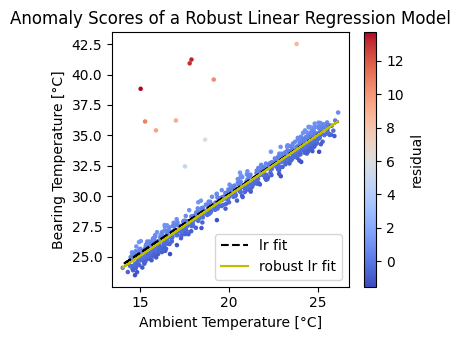

In [14]:
# Visualize the data in feature space (Ambient vs Bearing Temperature) and color by anomaly score
plt.figure(figsize=(4, 3.5))
# Scatter plot with color representing anomaly score
scatter = plt.scatter(data["Ambient Temperature"], data["Bearing Temperature"], c=residuals2, cmap='coolwarm',  s=5)
# Add color bar to indicate anomaly score levels
plt.colorbar(scatter, label='residual')
# plot the predictions of the two linear regressors
plt.plot(data["Ambient Temperature"],predictions1,'k--',label='lr fit')
plt.plot(data["Ambient Temperature"],predictions2,'y',label='robust lr fit')
# Labels and title
plt.title("Anomaly Scores of a Robust Linear Regression Model")
plt.legend()
plt.xlabel("Ambient Temperature [°C]")
plt.ylabel("Bearing Temperature [°C]")
plt.tight_layout()
#plt.savefig('BearingTemp_AnomalyScoresRobust.pdf')  # Save the figure
# Download the figure
#files.download('BearingTemp_AnomalyScoresRobust.pdf')
# Show plot
plt.show()


## plot residuals

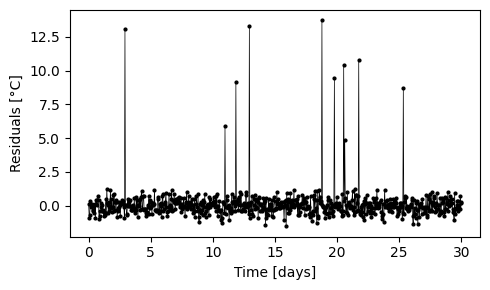

In [15]:
plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],residuals2,'k-o',lw=0.5,ms=2)
plt.ylabel("Residuals")
plt.xlabel('Time [days]')
plt.ylabel('Residuals [°C]')
plt.tight_layout()
#plt.savefig('BearingTempResiduals.pdf')  # Save the figure
# Download the figure
#files.download('BearingTempResiduals.pdf')

## Think
1. Does the problem seem familiar? Hint: how many dimensions do we have now?
2. How would you detect anomalies now?

## Statistical threshold on residuals

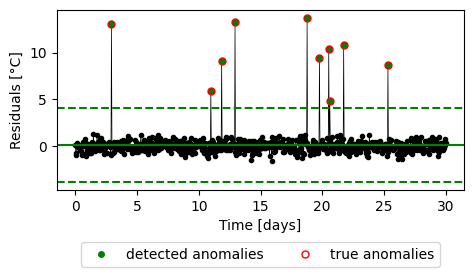

In [16]:
# calculate empirical mean and std of the residuals
temp_mean,temp_std = np.mean(residuals2),np.std(residuals2)
# define upper and lower thresholds
threshold_up = temp_mean+3*temp_std
threshold_low = temp_mean-3*temp_std
# detect anomalies using the thresholds
detect = (residuals2>threshold_up) |  (residuals2<threshold_low)
detected_anomalies = data[detect==1]
# use true labels only for plotting (not for modelling)
true_anomalies = data[data['Label']==1]

# plot the residual time series
plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],residuals2,'k-o',lw=0.5,ms=3)
# plot decision boundaries
plt.axhline(y=temp_mean,color='g')
plt.axhline(temp_mean+3*temp_std,color='g',ls='--')
plt.axhline(temp_mean-3*temp_std,color='g',ls='--')
# plot detected anomalies
plt.plot(detected_anomalies['Time (days)'],detected_anomalies['Residuals (Robust)'],'go',ms=4,label='detected anomalies')
# compare with the true labels (unused when modelling)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Residuals (Robust)'],'ro',markerfacecolor='none',ms=5,label='true anomalies')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.xlabel('Time [days]')
plt.ylabel('Residuals [°C]')
plt.tight_layout()
#plt.savefig('BearingTempResidualsStatThresh.pdf')  # Save the figure
# Download the figure
#files.download('BearingTempResidualsStatThresh.pdf')
# Show the plot
plt.show()


## Plot the original data with the detected anomalies

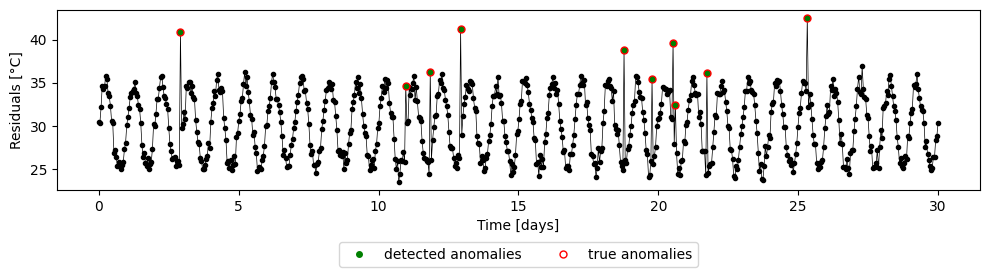

In [17]:
plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(detected_anomalies['Time (days)'],detected_anomalies['Bearing Temperature'],'go',ms=4,label='detected anomalies')
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=5,label='true anomalies')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.xlabel('Time [days]')
plt.ylabel('Residuals [°C]')
plt.tight_layout()
#plt.savefig('BearingTempDetection.pdf')  # Save the figure
# Download the figure
#files.download('BearingTempDetection.pdf')
# Show the plot
plt.show()

# Robust anomaly detection

Univariate case: What happens if we have more anomalies?

In [20]:
url_more_anomalies = "https://drive.google.com/uc?export=download&id=1kQd7NoUNL1kfvovBWuTzVg0nivqVZGSp"

# Load the CSV into a DataFrame directly from the URL
data = pd.read_csv(url_more_anomalies)

# Display the data to confirm
data

,Time (days),Bearing Temperature,Label
0,0.000000,30.124179,0.0
1,0.041725,29.965434,0.0
2,0.083449,30.161922,0.0
3,0.125174,30.380757,0.0
4,0.166898,29.941462,0.0
...,...,...,...
715,29.833102,30.275825,0.0
716,29.874826,30.028557,0.0
717,29.916551,30.037575,0.0
718,29.958275,29.909097,0.0


## visualize data

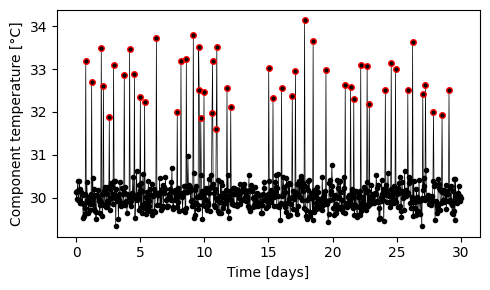

In [21]:
# Highlight true anomalies with large empty yellow squares
true_anomalies = data[data['Label']==1]  # Use the indices of the true anomalies


plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=4)
plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.tight_layout()
#plt.savefig('BearingTempIsolated.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('BearingTempIsolated.pdf')

## Calculate statistical threshold

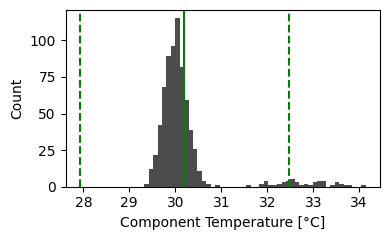

In [22]:
# calculate sample mean and std
temp_mean,temp_std = np.mean(data['Bearing Temperature']),np.std(data['Bearing Temperature'])
# determine upper and lower thresholds
threshold_up = temp_mean+3*temp_std
threshold_low = temp_mean-3*temp_std
# detect anomalies using the boundaries
detect = (data['Bearing Temperature']>threshold_up) |  (data['Bearing Temperature']<threshold_low)
detected_anomalies = data[detect==1]


# plot histogram with decision boundary
plt.figure(figsize=(4,2.5))
BearTempHist = plt.hist(data['Bearing Temperature'],50,color='k',alpha=0.7)

plt.axvline(temp_mean,color='g')
plt.axvline(threshold_up,color='g',ls='--')
plt.axvline(threshold_low,color='g',ls='--')

plt.xlabel('Component Temperature [°C]')
plt.ylabel('Count')

plt.tight_layout()
#plt.savefig('BearingTempIsolated_hist.pdf')  # Save the figure
plt.show()
# Download the figure
#files.download('BearingTempIsolated_hist.pdf')

## Visualize the detection results

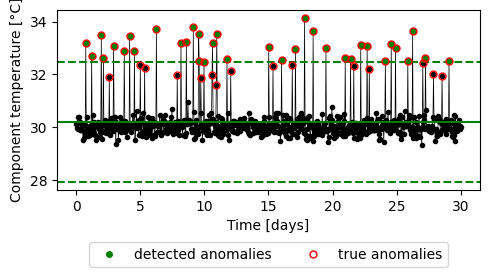

In [23]:
# plot time series data with decision boundary
plt.figure(figsize=(5,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)

plt.axhline(y=temp_mean,color='g')
plt.axhline(threshold_up,color='g',ls='--')
plt.axhline(threshold_low,color='g',ls='--')

# mark detected anomalies
plt.plot(detected_anomalies['Time (days)'],detected_anomalies['Bearing Temperature'],'go',ms=4,label='detected anomalies')
# compare with true anomalies
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=5,label='true anomalies')

plt.xlabel('Time [days]')
plt.ylabel('Component temperature [°C]')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)

plt.tight_layout()
#plt.savefig('BearingTempIsolated_statThresh.pdf')  # Save the figure
plt.show()
# Download the figure
#files.download('BearingTempIsolated_statThresh.pdf')

Think
1. why did this happened?
2. How would you solve this?


## Solution: robust thresholding

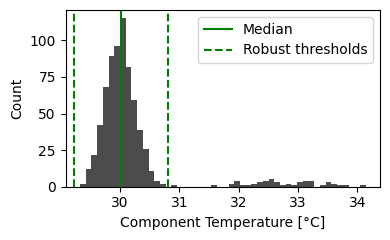

In [24]:


temperature = data["Bearing Temperature"]

# Robust estimates of center and spread
temp_median = np.median(temperature)

mad = np.median(
    np.abs(temperature - temp_median)
)

# Scale MAD so that it is comparable to the standard deviation
# for approximately Gaussian data
robust_std = 1.4826 * mad

# Robust upper and lower thresholds
threshold_up = temp_median + 3 * robust_std
threshold_low = temp_median - 3 * robust_std

# Detect anomalies outside the robust boundaries
detect = (
    (temperature > threshold_up)
    | (temperature < threshold_low)
)

detected_anomalies = data[detect]

# Plot histogram with robust decision boundaries
plt.figure(figsize=(4, 2.5))

plt.hist(
    temperature,
    bins=50,
    color="k",
    alpha=0.7
)

plt.axvline(
    temp_median,
    color="g",
    label="Median"
)

plt.axvline(
    threshold_up,
    color="g",
    linestyle="--",
    label="Robust thresholds"
)

plt.axvline(
    threshold_low,
    color="g",
    linestyle="--"
)

plt.xlabel("Component Temperature [°C]")
plt.ylabel("Count")
plt.legend()

plt.tight_layout()
plt.show()

## Visualize robust thresholding results

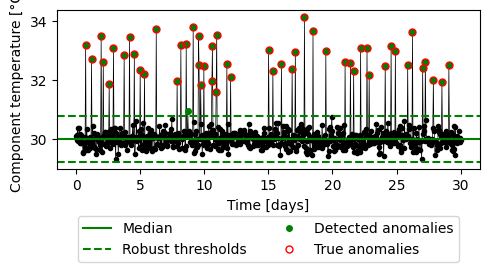

In [25]:
# Plot time-series data with robust decision boundaries
plt.figure(figsize=(5, 3))

plt.plot(
    data["Time (days)"],
    data["Bearing Temperature"],
    "k-o",
    lw=0.5,
    ms=3
)

# Robust center and thresholds
plt.axhline(
    y=temp_median,
    color="g",
    label="Median"
)

plt.axhline(
    y=threshold_up,
    color="g",
    linestyle="--",
    label="Robust thresholds"
)

plt.axhline(
    y=threshold_low,
    color="g",
    linestyle="--"
)

# Mark detected anomalies
plt.plot(
    detected_anomalies["Time (days)"],
    detected_anomalies["Bearing Temperature"],
    "go",
    ms=4,
    label="Detected anomalies"
)

# Compare with true anomalies
plt.plot(
    true_anomalies["Time (days)"],
    true_anomalies["Bearing Temperature"],
    "ro",
    markerfacecolor="none",
    ms=5,
    label="True anomalies"
)

plt.xlabel("Time [days]")
plt.ylabel("Component temperature [°C]")

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=2
)

plt.tight_layout()
plt.show()

# Robust multivariate anomaly detection

## Read data

In [54]:
url = "https://drive.google.com/uc?export=download&id=1ci52O_09l91TxUDU3vIshMVvobaK3rdS" #both strong and weka anomalies
#url = "https://drive.google.com/uc?export=download&id=1XcxtZPidYO7pvXqxoIDH9yyvHPpwh3S6"
#url = "https://drive.google.com/uc?export=download&id=1JrZQrpBnaQ0Xvf88oDHmjwWxiJWNZcmM"

# Load the CSV into a DataFrame directly from the URL
data = pd.read_csv(url)

# Display the data to confirm
data


,Time (days),Ambient Temperature,Bearing Temperature,Label
0,0.000000,20.248357,30.402258,0.0
1,0.041725,21.226722,31.898497,1.0
2,0.083449,22.826997,32.152904,0.0
3,0.125174,24.300909,34.672541,0.0
4,0.166898,24.216687,34.302120,0.0
...,...,...,...,...
715,29.833102,16.217887,26.359177,0.0
716,29.874826,16.517720,26.393374,0.0
717,29.916551,17.571998,28.375671,0.0
718,29.958275,18.522340,28.767828,0.0


## Visualize data

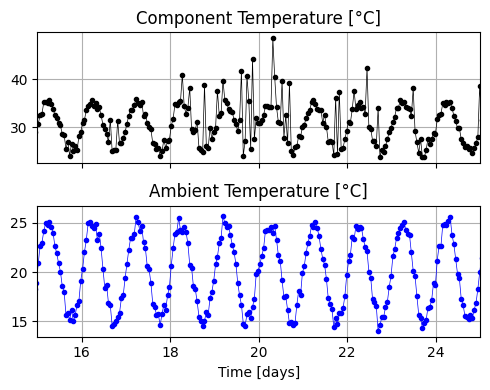

In [55]:
# Create subplots for the variables
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(5, 4), sharex=True)
xlimit = [15,25]
# Plot bearing temperature
axes[0].plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
axes[0].set_title("Component Temperature [°C]")
axes[0].grid(True)
axes[0].set_xlim(xlimit)
# Plot ambient temperature
axes[1].plot(data['Time (days)'], data['Ambient Temperature'],'b-o',lw=0.5,ms=3)
axes[1].set_xlabel("Time [days]")
axes[1].set_title("Ambient Temperature [°C]")
axes[1].grid(True)
plt.tight_layout()
#plt.savefig('BearingTempAmbientTemp.pdf')  # Save the figure
# Download the figure
#files.download('BearingTempAmbientTemp.pdf')

plt.show()

## Correlation plots

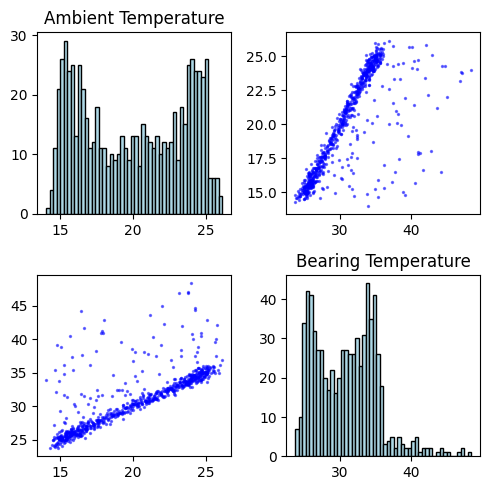

<Figure size 640x480 with 0 Axes>

In [56]:
var_data = data[["Ambient Temperature","Bearing Temperature"]].copy()
fig,axes = pair_plot(var_data)

plt.tight_layout()
fig.savefig('BearingTempAmbient_PairPlot.pdf')  # Save the figure


## Linear regression

In [57]:
# Prepare the features and target
X = data['Ambient Temperature'].values.reshape(-1, 1)  # Feature: Ambient Temperature
y = data['Bearing Temperature'].values  # Target: Bearing Temperature

# Fit model 1 - Simple Linear Regression
model1 = LinearRegression()
model1.fit(X, y)
predictions1 = model1.predict(X)

# Calculate residuals for model 1
residuals1 = y - predictions1

# Add residuals as anomaly scores to the dataset
data['Residuals (Linear)'] = residuals1


## Robust linear regression

In [58]:
# Fit model 2 - Robust Linear Regression (HuberRegressor)
model2 = HuberRegressor()
model2.fit(X, y)
predictions2 = model2.predict(X)

# Calculate residuals for model 2
residuals2 = y - predictions2

# Add residuals as anomaly scores to the dataset
data['Residuals (Robust)'] = residuals2

## Plot both fits

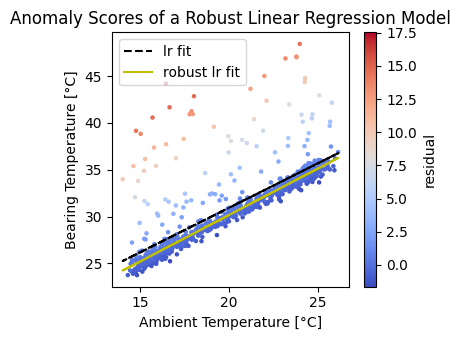

In [59]:
# Visualize the data in feature space (Ambient vs Bearing Temperature) and color by anomaly score
plt.figure(figsize=(4, 3.5))
# Scatter plot with color representing anomaly score
scatter = plt.scatter(data["Ambient Temperature"], data["Bearing Temperature"], c=residuals2, cmap='coolwarm',  s=5)
# Add color bar to indicate anomaly score levels
plt.colorbar(scatter, label='residual')
# plot the predictions of the two linear regressors
plt.plot(data["Ambient Temperature"],predictions1,'k--',label='lr fit')
plt.plot(data["Ambient Temperature"],predictions2,'y',label='robust lr fit')
# Labels and title
plt.title("Anomaly Scores of a Robust Linear Regression Model")
plt.legend()
plt.xlabel("Ambient Temperature [°C]")
plt.ylabel("Bearing Temperature [°C]")
plt.tight_layout()
#plt.savefig('BearingTemp_AnomalyScoresRobust.pdf')  # Save the figure
# Download the figure
#files.download('BearingTemp_AnomalyScoresRobust.pdf')
# Show plot
plt.show()

## Plot residuals

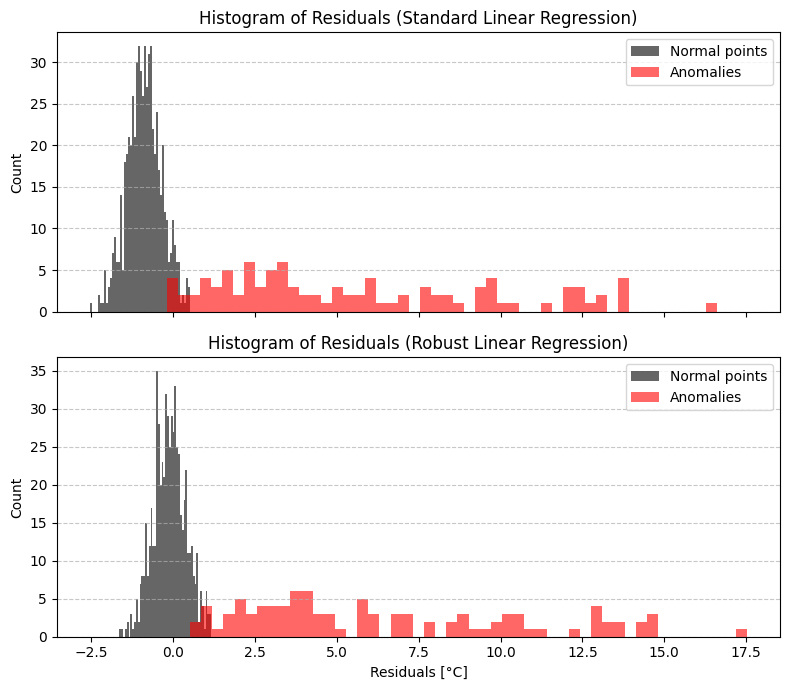

In [82]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# Create a boolean mask for anomalies
is_anomaly = data['Label'] == 1

# Plot histogram for residuals1 (Standard Linear Regression)
axes[0].hist(residuals1[~is_anomaly], bins=50, color='black', alpha=0.6, label='Normal points')
axes[0].hist(residuals1[is_anomaly], bins=50, color='red', alpha=0.6, label='Anomalies')
axes[0].set_title('Histogram of Residuals (Standard Linear Regression)')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot histogram for residuals2 (Robust Linear Regression)
axes[1].hist(residuals2[~is_anomaly], bins=50, color='black', alpha=0.6, label='Normal points')
axes[1].hist(residuals2[is_anomaly], bins=50, color='red', alpha=0.6, label='Anomalies')
axes[1].set_title('Histogram of Residuals (Robust Linear Regression)')
axes[1].set_xlabel('Residuals [°C]')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

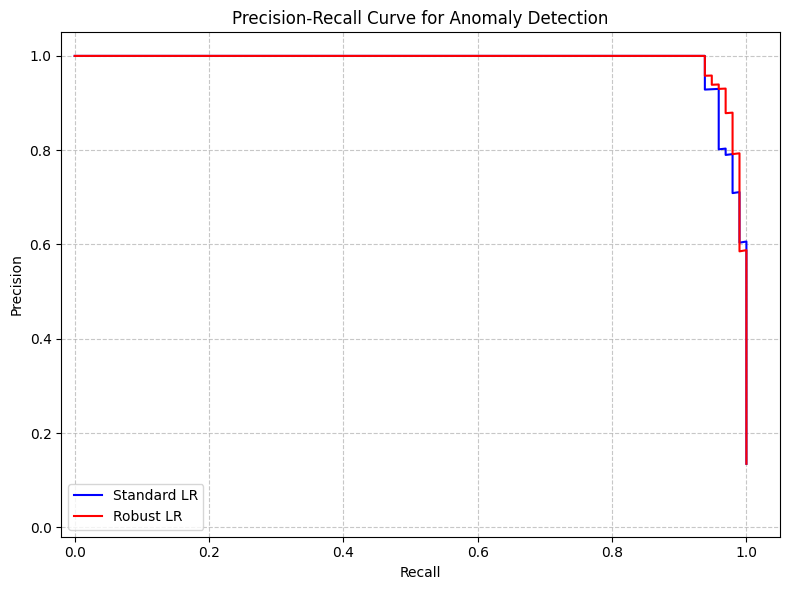

In [85]:
from sklearn.metrics import precision_recall_curve

# Anomaly scores are the absolute residuals
#anomaly_scores1 = np.abs(residuals1)
#anomaly_scores2 = np.abs(residuals2)


anomaly_scores1 = residuals1
anomaly_scores2 = residuals2

# True labels
y_true = data['Label']

# Calculate Precision-Recall for Model 1 (Standard Linear Regression)
precision1, recall1, _ = precision_recall_curve(y_true, anomaly_scores1)

# Calculate Precision-Recall for Model 2 (Robust Linear Regression)
precision2, recall2, _ = precision_recall_curve(y_true, anomaly_scores2)

# Plotting the Precision-Recall curves
plt.figure(figsize=(8, 6))
plt.plot(recall1, precision1, label='Standard LR', color='blue')
plt.plot(recall2, precision2, label='Robust LR', color='red')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Anomaly Detection')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim([-0.02, 1.05]) # Adjusted x-limit
plt.ylim([-0.02, 1.05]) # Adjusted y-limit
plt.tight_layout()
plt.show()

## Anomaly Detection with Robust Thresholding

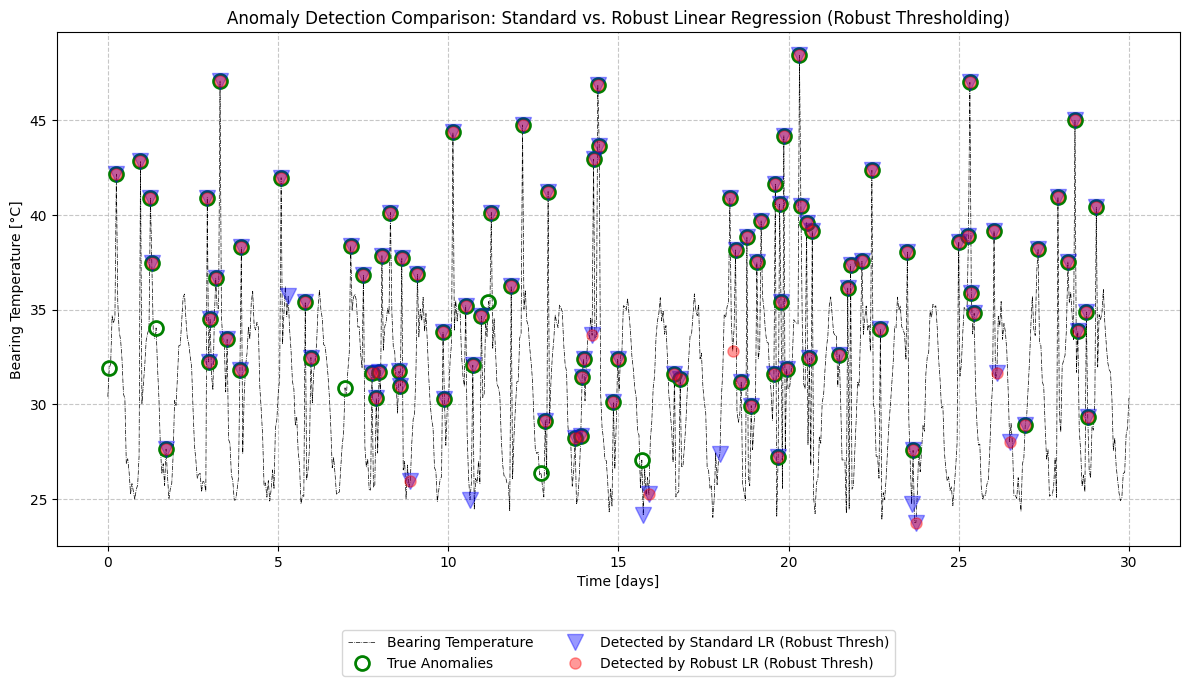

In [84]:
# --- Robust Thresholding for Standard Linear Regression Residuals (residuals1) ---

res1_median = np.median(residuals1)
res1_mad = np.median(np.abs(residuals1 - res1_median))
res1_robust_std = 1.4826 * res1_mad # Scale MAD to be comparable to std for Gaussian data

res1_threshold_up_robust = res1_median + 2 * res1_robust_std
res1_threshold_low_robust = res1_median - 2 * res1_robust_std

detect1_robust = (residuals1 > res1_threshold_up_robust) | (residuals1 < res1_threshold_low_robust)
detected_anomalies1_robust = data[detect1_robust]


# --- Robust Thresholding for Robust Linear Regression Residuals (residuals2) ---

res2_median = np.median(residuals2)
res2_mad = np.median(np.abs(residuals2 - res2_median))
res2_robust_std = 1.4826 * res2_mad # Scale MAD to be comparable to std for Gaussian data

res2_threshold_up_robust = res2_median + 2 * res2_robust_std
res2_threshold_low_robust = res2_median - 2 * res2_robust_std

detect2_robust = (residuals2 > res2_threshold_up_robust) | (residuals2 < res2_threshold_low_robust)
detected_anomalies2_robust = data[detect2_robust]


# --- True anomalies for plotting ---
true_anomalies = data[data['Label'] == 1]


# --- Plotting ---
plt.figure(figsize=(12, 7))

# Plot original bearing temperature
plt.plot(data['Time (days)'], data['Bearing Temperature'], 'k-.', lw=0.5, ms=3, label='Bearing Temperature')

# Plot true anomalies (green circles)
plt.plot(true_anomalies['Time (days)'], true_anomalies['Bearing Temperature'], 'go', markerfacecolor='none', ms=10, mew=2, label='True Anomalies')

# Plot anomalies detected by Standard LR with Robust Thresholding (blue squares, transparent)
plt.plot(detected_anomalies1_robust['Time (days)'], detected_anomalies1_robust['Bearing Temperature'], 'v', color='blue', alpha=0.4, ms=12, label='Detected by Standard LR (Robust Thresh)')

# Plot anomalies detected by Robust LR with Robust Thresholding (red 'x' marks, transparent)
plt.plot(detected_anomalies2_robust['Time (days)'], detected_anomalies2_robust['Bearing Temperature'], 'o', color='red', alpha=0.4, ms=8, label='Detected by Robust LR (Robust Thresh)')

plt.xlabel('Time [days]')
plt.ylabel('Bearing Temperature [°C]')
plt.title('Anomaly Detection Comparison: Standard vs. Robust Linear Regression (Robust Thresholding)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()